<a href="https://colab.research.google.com/github/anavi-lira/phishing-detection-rf-distilbert-ensemble/blob/main/phishing_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Miniprojeto — Detecção de Phishing com Random Forest + DistilBERT + Ensemble

Este notebook reproduz, em escala reduzida, uma comparação entre:

- **Random Forest + TF-IDF**
- **DistilBERT**
- **Ensemble híbrido Random Forest + DistilBERT**

A modificação proposta é combinar as probabilidades dos dois modelos em um **ensemble ponderado**.

Artigo-base:

**Tarapiah et al. (2025). _Evaluating the Effectiveness of Large Language Models (LLMs) Versus Machine Learning (ML) in Identifying and Detecting Phishing Email Attempts_. Algorithms, 18(10), 599.**

## Antes de começar

No Google Colab:

**Ambiente de execução → Alterar tipo de ambiente de execução → GPU**

Depois execute as células de cima para baixo.


In [27]:
import torch

print("PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: nenhuma GPU foi detectada. O DistilBERT ficará mais lento.")


PyTorch: 2.14.1+cu130
GPU disponível: True
GPU: Tesla T4


## 1. Instalação das bibliotecas

In [28]:
!pip -q install -U datasets transformers accelerate scikit-learn pandas matplotlib seaborn beautifulsoup4 joblib


## 2. Configuração do experimento

Configuração padrão:

- 5.000 e-mails
- 60% treino
- 20% validação
- 20% teste

Se quiser testar mais rápido, troque `MAX_SAMPLES = 5000` por `2000`.


In [29]:
SEED = 42
MAX_SAMPLES = 5000

TRAIN_RATIO = 0.60
VAL_RATIO = 0.20
TEST_RATIO = 0.20

TFIDF_MAX_FEATURES = 20000

DISTILBERT_MODEL = "distilbert-base-uncased"
MAX_LENGTH = 256
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

ENSEMBLE_WEIGHT_STEP = 0.05
THRESHOLD = 0.50

print("Configuração carregada.")


Configuração carregada.


## 3. Imports e funções auxiliares

In [8]:
import os
import re
import json
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from bs4 import BeautifulSoup
from datasets import load_dataset, Dataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)

warnings.filterwarnings("ignore")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

def classification_metrics(y_true, y_pred, y_prob=None):
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

    if y_prob is not None and len(np.unique(y_true)) == 2:
        result["roc_auc"] = roc_auc_score(y_true, y_prob)

    return result

def show_metrics(name, metrics):
    print(f"\n{name}")
    for k, v in metrics.items():
        print(f"{k:20s}: {v:.4f}")


## 4. Download da base de dados

O notebook tenta usar a base pública:

`zefang-liu/phishing-email-dataset`


In [9]:
DATASET_NAME = "zefang-liu/phishing-email-dataset"

dataset = load_dataset(DATASET_NAME, split="train")

print(dataset)
print("\nColunas disponíveis:")
print(dataset.column_names)

df_raw = dataset.to_pandas()
display(df_raw.head())


README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

Dataset({
    features: ['Unnamed: 0', 'Email Text', 'Email Type'],
    num_rows: 18650
})

Colunas disponíveis:
['Unnamed: 0', 'Email Text', 'Email Type']


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


## 5. Padronização e preparação dos dados

In [10]:
TEXT_COLUMN = "Email Text"
LABEL_COLUMN = "Email Type"

if TEXT_COLUMN not in df_raw.columns or LABEL_COLUMN not in df_raw.columns:
    raise ValueError(
        f"Colunas esperadas não encontradas. Disponíveis: {list(df_raw.columns)}"
    )

def normalize_label(value):
    text = str(value).strip().lower()

    if text in {"1", "1.0", "phishing", "phishing email", "malicious", "fraud"}:
        return 1

    if text in {"0", "0.0", "safe", "safe email", "legitimate", "legitimate email", "ham", "benign"}:
        return 0

    if "phish" in text or "fraud" in text or "malicious" in text:
        return 1

    if "safe" in text or "legit" in text or "benign" in text or text == "ham":
        return 0

    raise ValueError(f"Rótulo não reconhecido: {value}")

df = df_raw[[TEXT_COLUMN, LABEL_COLUMN]].copy()
df.columns = ["text", "raw_label"]

df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"].str.len() > 0].copy()
df["label"] = df["raw_label"].apply(normalize_label)
df = df.drop(columns=["raw_label"])
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Após limpeza:", len(df))
print(df["label"].value_counts())


Após limpeza: 17522
label
0    10978
1     6544
Name: count, dtype: int64


## 6. Seleção do subconjunto e divisão 60/20/20

In [11]:
if MAX_SAMPLES is not None and MAX_SAMPLES < len(df):
    df, _ = train_test_split(
        df,
        train_size=MAX_SAMPLES,
        random_state=SEED,
        stratify=df["label"]
    )

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df["row_id"] = np.arange(len(df))

temp_ratio = VAL_RATIO + TEST_RATIO

train_df, temp_df = train_test_split(
    df,
    test_size=temp_ratio,
    random_state=SEED,
    stratify=df["label"]
)

relative_test = TEST_RATIO / temp_ratio

val_df, test_df = train_test_split(
    temp_df,
    test_size=relative_test,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Treino:", len(train_df))
print(train_df["label"].value_counts().sort_index())
print("\nValidação:", len(val_df))
print(val_df["label"].value_counts().sort_index())
print("\nTeste:", len(test_df))
print(test_df["label"].value_counts().sort_index())


Treino: 3000
label
0    1880
1    1120
Name: count, dtype: int64

Validação: 1000
label
0    626
1    374
Name: count, dtype: int64

Teste: 1000
label
0    627
1    373
Name: count, dtype: int64


## 7. Random Forest + TF-IDF

In [12]:
def clean_for_rf(text):
    text = BeautifulSoup(str(text), "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)
    text = re.sub(r"\S+@\S+", " email ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

rf_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=clean_for_rf,
            stop_words="english",
            max_features=TFIDF_MAX_FEATURES,
            ngram_range=(1, 2),
            sublinear_tf=True,
        )
    ),
    (
        "rf",
        RandomForestClassifier(
            random_state=SEED,
            n_jobs=-1
        )
    )
])

rf_param_grid = {
    "rf__n_estimators": [200, 400],
    "rf__max_depth": [None, 30],
    "rf__min_samples_split": [2, 5],
    "rf__class_weight": [None, "balanced"],
}

rf_search = GridSearchCV(
    rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1,
)

rf_search.fit(train_df["text"], train_df["label"])

rf_model = rf_search.best_estimator_

print("Melhores parâmetros:")
print(rf_search.best_params_)

joblib.dump(rf_model, "models/random_forest.joblib")


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Melhores parâmetros:
{'rf__class_weight': None, 'rf__max_depth': None, 'rf__min_samples_split': 2, 'rf__n_estimators': 200}


['models/random_forest.joblib']

## 8. Avaliação do Random Forest

In [13]:
rf_val_prob = rf_model.predict_proba(val_df["text"])[:, 1]
rf_val_pred = (rf_val_prob >= THRESHOLD).astype(int)

rf_test_prob = rf_model.predict_proba(test_df["text"])[:, 1]
rf_test_pred = (rf_test_prob >= THRESHOLD).astype(int)

rf_val_metrics = classification_metrics(
    val_df["label"].values,
    rf_val_pred,
    rf_val_prob
)

rf_test_metrics = classification_metrics(
    test_df["label"].values,
    rf_test_pred,
    rf_test_prob
)

show_metrics("Random Forest — validação", rf_val_metrics)
show_metrics("Random Forest — teste", rf_test_metrics)



Random Forest — validação
accuracy            : 0.9640
precision           : 0.9333
recall              : 0.9733
f1                  : 0.9529
balanced_accuracy   : 0.9659
roc_auc             : 0.9927

Random Forest — teste
accuracy            : 0.9660
precision           : 0.9472
recall              : 0.9625
f1                  : 0.9548
balanced_accuracy   : 0.9653
roc_auc             : 0.9950


## 9. DistilBERT — Transfer Learning

O modelo utilizado é `distilbert-base-uncased`.


In [14]:
tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL)

def dataframe_to_dataset(dataframe):
    ds = Dataset.from_pandas(
        dataframe[["row_id", "text", "label"]],
        preserve_index=False
    )

    def tokenize(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH
        )

    ds = ds.map(tokenize, batched=True)
    ds = ds.rename_column("label", "labels")
    return ds

train_ds = dataframe_to_dataset(train_df)
val_ds = dataframe_to_dataset(val_df)
test_ds = dataframe_to_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_MODEL,
    num_labels=2
)

print("DistilBERT carregado.")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT carregado.


## 10. Configuração e treino do DistilBERT

In [15]:
def compute_metrics_transformer(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(labels, preds),
    }

training_args = TrainingArguments(
    output_dir="models/distilbert_checkpoints",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics_transformer,
)

trainer.train()

trainer.save_model("models/distilbert")
tokenizer.save_pretrained("models/distilbert")

print("Treinamento concluído.")


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Balanced Accuracy
1,0.108672,0.172690,0.938000,0.993671,0.839572,0.910145,0.918189
2,0.052726,0.074113,0.981000,0.970822,0.978610,0.974700,0.980519
3,0.015923,0.074100,0.982000,0.981081,0.970588,0.975806,0.979703


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Treinamento concluído.


## 11. Avaliação do DistilBERT

In [16]:
def positive_probability(logits):
    tensor = torch.tensor(logits)
    return torch.softmax(tensor, dim=1).numpy()[:, 1]

val_output = trainer.predict(val_ds)
test_output = trainer.predict(test_ds)

distil_val_prob = positive_probability(val_output.predictions)
distil_test_prob = positive_probability(test_output.predictions)

distil_val_pred = (distil_val_prob >= THRESHOLD).astype(int)
distil_test_pred = (distil_test_prob >= THRESHOLD).astype(int)

distil_val_metrics = classification_metrics(
    val_df["label"].values,
    distil_val_pred,
    distil_val_prob
)

distil_test_metrics = classification_metrics(
    test_df["label"].values,
    distil_test_pred,
    distil_test_prob
)

show_metrics("DistilBERT — validação", distil_val_metrics)
show_metrics("DistilBERT — teste", distil_test_metrics)



DistilBERT — validação
accuracy            : 0.9820
precision           : 0.9811
recall              : 0.9706
f1                  : 0.9758
balanced_accuracy   : 0.9797
roc_auc             : 0.9983

DistilBERT — teste
accuracy            : 0.9790
precision           : 0.9809
recall              : 0.9625
f1                  : 0.9716
balanced_accuracy   : 0.9757
roc_auc             : 0.9979


# 12. Modificação proposta — Ensemble híbrido

\[
P_{final} = \alpha P_{RF} + (1-\alpha)P_{DistilBERT}
\]

O peso α é escolhido no conjunto de validação buscando o maior F1-score.


In [17]:
best = None

for alpha in np.arange(0.0, 1.0 + ENSEMBLE_WEIGHT_STEP / 2, ENSEMBLE_WEIGHT_STEP):
    ensemble_val_prob = (
        alpha * rf_val_prob
        + (1.0 - alpha) * distil_val_prob
    )

    ensemble_val_pred = (
        ensemble_val_prob >= THRESHOLD
    ).astype(int)

    score = f1_score(
        val_df["label"].values,
        ensemble_val_pred,
        zero_division=0
    )

    if best is None or score > best["f1"]:
        best = {
            "alpha_rf": float(alpha),
            "alpha_distilbert": float(1.0 - alpha),
            "f1": float(score)
        }

best


{'alpha_rf': 0.7000000000000001,
 'alpha_distilbert': 0.29999999999999993,
 'f1': 0.9813829787234043}

## 13. Ensemble 50/50 e Ensemble ponderado

In [18]:
alpha_rf = best["alpha_rf"]
alpha_distil = best["alpha_distilbert"]

ensemble_50_prob = (
    0.5 * rf_test_prob
    + 0.5 * distil_test_prob
)

ensemble_50_pred = (
    ensemble_50_prob >= THRESHOLD
).astype(int)

ensemble_weighted_prob = (
    alpha_rf * rf_test_prob
    + alpha_distil * distil_test_prob
)

ensemble_weighted_pred = (
    ensemble_weighted_prob >= THRESHOLD
).astype(int)

ensemble_50_metrics = classification_metrics(
    test_df["label"].values,
    ensemble_50_pred,
    ensemble_50_prob
)

ensemble_weighted_metrics = classification_metrics(
    test_df["label"].values,
    ensemble_weighted_pred,
    ensemble_weighted_prob
)

show_metrics("Ensemble 50/50 — teste", ensemble_50_metrics)
show_metrics("Ensemble ponderado — teste", ensemble_weighted_metrics)

print("\nPesos escolhidos na validação:")
print("Random Forest:", round(alpha_rf, 2))
print("DistilBERT:", round(alpha_distil, 2))



Ensemble 50/50 — teste
accuracy            : 0.9810
precision           : 0.9836
recall              : 0.9651
f1                  : 0.9743
balanced_accuracy   : 0.9778
roc_auc             : 0.9990

Ensemble ponderado — teste
accuracy            : 0.9860
precision           : 0.9787
recall              : 0.9839
f1                  : 0.9813
balanced_accuracy   : 0.9856
roc_auc             : 0.9988

Pesos escolhidos na validação:
Random Forest: 0.7
DistilBERT: 0.3


## 14. Tabela comparativa final

In [19]:
comparison = pd.DataFrame([
    {"Modelo": "Random Forest", **rf_test_metrics},
    {"Modelo": "DistilBERT", **distil_test_metrics},
    {"Modelo": "Ensemble 50/50", **ensemble_50_metrics},
    {"Modelo": "Ensemble ponderado", **ensemble_weighted_metrics},
])

comparison = comparison[
    [
        "Modelo",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "roc_auc",
    ]
]

display(comparison.round(4))
comparison.to_csv("results/model_comparison.csv", index=False)


,Modelo,accuracy,precision,recall,f1,balanced_accuracy,roc_auc
0,Random Forest,0.966,0.9472,0.9625,0.9548,0.9653,0.9950
1,DistilBERT,0.979,0.9809,0.9625,0.9716,0.9757,0.9979
2,Ensemble 50/50,0.981,0.9836,0.9651,0.9743,0.9778,0.9990
3,Ensemble ponderado,0.986,0.9787,0.9839,0.9813,0.9856,0.9988


## 15. Gráfico comparativo

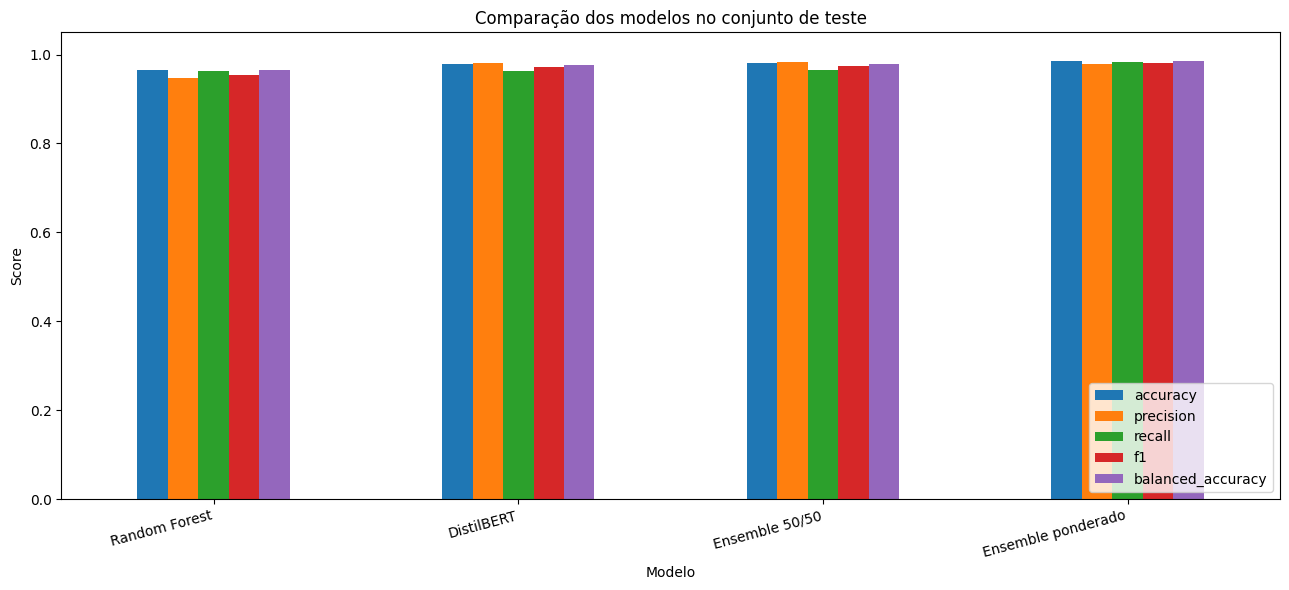

In [20]:
plot_df = comparison.set_index("Modelo")

metrics_to_plot = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
]

ax = plot_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Comparação dos modelos no conjunto de teste")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("results/model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 16. Matrizes de confusão

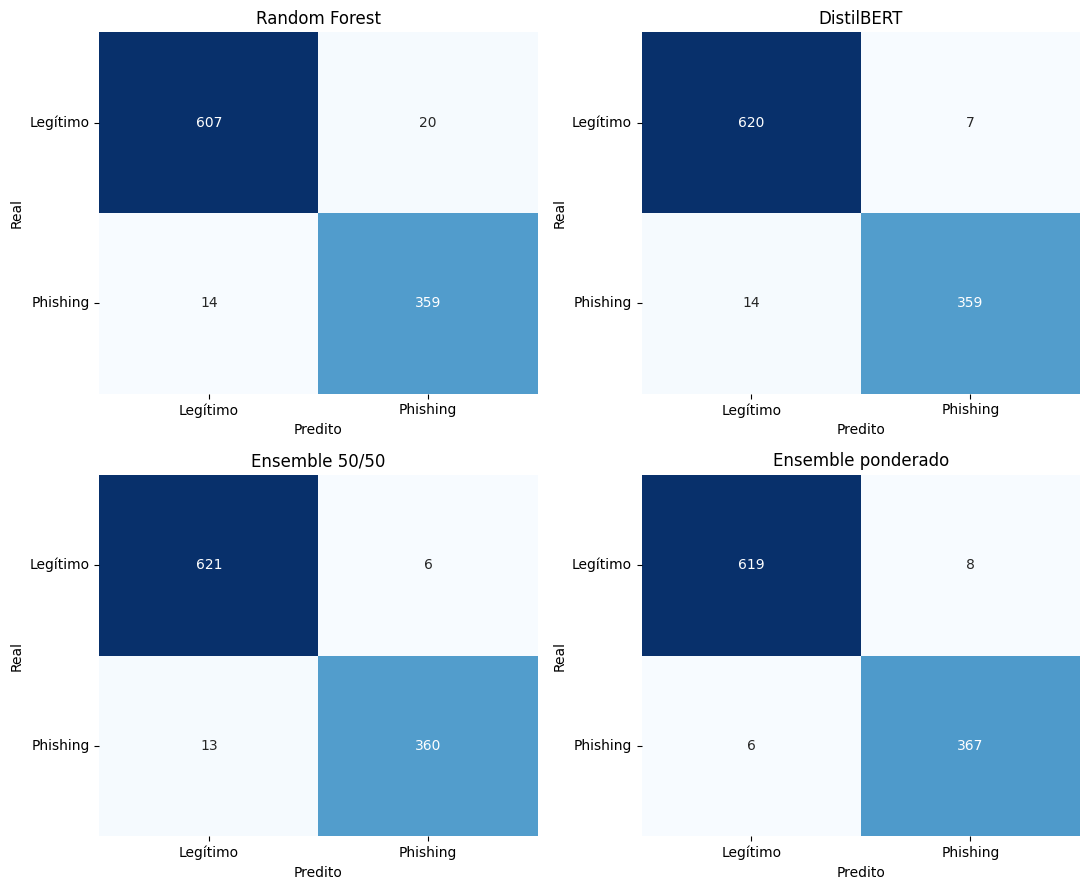

In [21]:
models_preds = {
    "Random Forest": rf_test_pred,
    "DistilBERT": distil_test_pred,
    "Ensemble 50/50": ensemble_50_pred,
    "Ensemble ponderado": ensemble_weighted_pred,
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, pred) in zip(axes.ravel(), models_preds.items()):
    cm = confusion_matrix(test_df["label"].values, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_xticklabels(["Legítimo", "Phishing"])
    ax.set_yticklabels(["Legítimo", "Phishing"], rotation=0)

plt.tight_layout()
plt.savefig("results/confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()


## 17. Relatório de classificação do ensemble proposto

In [22]:
print(
    classification_report(
        test_df["label"].values,
        ensemble_weighted_pred,
        target_names=["Legítimo", "Phishing"]
    )
)


              precision    recall  f1-score   support

    Legítimo       0.99      0.99      0.99       627
    Phishing       0.98      0.98      0.98       373

    accuracy                           0.99      1000
   macro avg       0.98      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



## 18. Salvar previsões

In [23]:
test_results = test_df[["row_id", "text", "label"]].copy()

test_results["rf_prob"] = rf_test_prob
test_results["distilbert_prob"] = distil_test_prob
test_results["ensemble_50_prob"] = ensemble_50_prob
test_results["ensemble_weighted_prob"] = ensemble_weighted_prob
test_results["ensemble_prediction"] = ensemble_weighted_pred

test_results.to_csv("results/test_predictions.csv", index=False)

with open("results/ensemble_config.json", "w") as f:
    json.dump(
        {
            "alpha_rf": alpha_rf,
            "alpha_distilbert": alpha_distil,
            "threshold": THRESHOLD,
            "best_validation_f1": best["f1"],
        },
        f,
        indent=2
    )

print("Arquivos salvos em results/")


Arquivos salvos em results/


# 19. Teste manual de um e-mail

Troque o texto de `email_text` pelo e-mail que deseja testar.


In [24]:
email_text = '''
URGENT: Your account has been suspended.
Click the link below immediately to verify your password and restore access.
'''

rf_manual_prob = rf_model.predict_proba([email_text])[:, 1][0]

encoded = tokenizer(
    email_text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

device = trainer.model.device
encoded = {k: v.to(device) for k, v in encoded.items()}

trainer.model.eval()

with torch.no_grad():
    logits = trainer.model(**encoded).logits
    distil_manual_prob = torch.softmax(logits, dim=1)[0, 1].item()

ensemble_manual_prob = (
    alpha_rf * rf_manual_prob
    + alpha_distil * distil_manual_prob
)

prediction = (
    "PHISHING"
    if ensemble_manual_prob >= THRESHOLD
    else "LEGÍTIMO"
)

print(f"Random Forest: {rf_manual_prob:.2%}")
print(f"DistilBERT:    {distil_manual_prob:.2%}")
print(f"Ensemble:      {ensemble_manual_prob:.2%}")
print(f"\nResultado final: {prediction}")


Random Forest: 89.00%
DistilBERT:    98.86%
Ensemble:      91.96%

Resultado final: PHISHING


## 20. Função para testar outros e-mails

In [25]:
def predict_email(text):
    rf_prob = rf_model.predict_proba([text])[:, 1][0]

    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=MAX_LENGTH
    )

    encoded = {k: v.to(trainer.model.device) for k, v in encoded.items()}

    trainer.model.eval()

    with torch.no_grad():
        logits = trainer.model(**encoded).logits
        db_prob = torch.softmax(logits, dim=1)[0, 1].item()

    ens_prob = alpha_rf * rf_prob + alpha_distil * db_prob
    label = "PHISHING" if ens_prob >= THRESHOLD else "LEGÍTIMO"

    return {
        "Random Forest": rf_prob,
        "DistilBERT": db_prob,
        "Ensemble": ens_prob,
        "Resultado": label
    }

legitimate_email = '''
Hi team,

The meeting scheduled for tomorrow has been moved to 10:30 AM.
Please check the calendar invitation for the updated room.

Best regards,
John
'''

predict_email(legitimate_email)


{'Random Forest': np.float64(0.355),
 'DistilBERT': 0.0011073390487581491,
 'Ensemble': np.float64(0.24883220171462744),
 'Resultado': 'LEGÍTIMO'}

## 21. Baixar os resultados do Colab

In [26]:
import shutil
from google.colab import files

shutil.make_archive(
    "resultados_miniprojeto",
    "zip",
    "results"
)

files.download("resultados_miniprojeto.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Como interpretar

Depois de rodar o notebook, compare principalmente:

- **F1-score**
- **Recall**
- **Balanced Accuracy**
- **ROC-AUC**

Se o ensemble superar os modelos individuais, isso favorece a modificação proposta.

Se não superar, o resultado continua válido: significa que, **neste conjunto e nesta configuração experimental**, a combinação não melhorou o melhor modelo individual.
